===== Participant Count =====
Emotional Appropriateness : 32명
Language Naturalness : 32명
Empathy : 32명

===== Statistics =====

[Emotional Appropriateness]
Mean   = 4.5625 → 4.6
Median = 5.0
SD     = 0.6189 → 0.62
Q1     = 4.0
Q3     = 5.0

[Language Naturalness]
Mean   = 4.7812 → 4.8
Median = 5.0
SD     = 0.4908 → 0.49
Q1     = 5.0
Q3     = 5.0

[Empathy]
Mean   = 4.5000 → 4.5
Median = 5.0
SD     = 0.6222 → 0.62
Q1     = 4.0
Q3     = 5.0


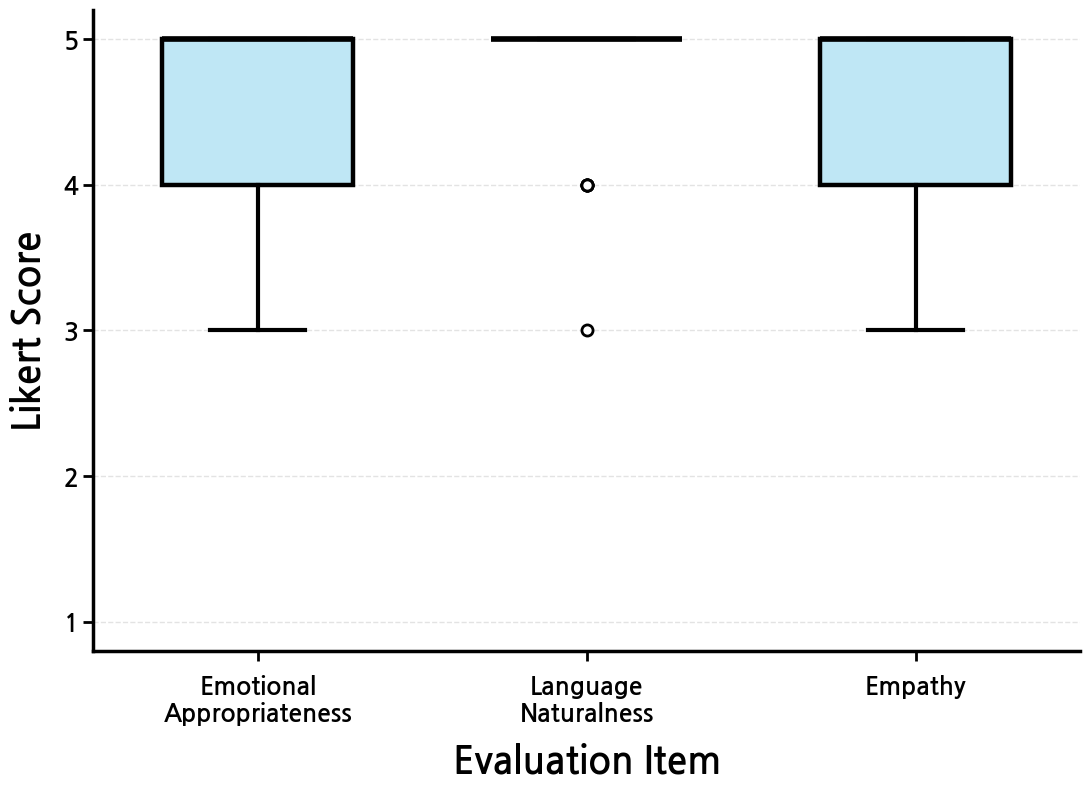


Saved to: /content/user_evaluation_boxplot_skyblue.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from google.colab import files

# ============================================================
# 1. NanumGothic 폰트 설치 및 설정
# ============================================================
!apt-get -qq install fonts-nanum

FONT_PATH = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
FONT_BOLD_PATH = "/usr/share/fonts/truetype/nanum/NanumGothicBold.ttf"

font_prop = fm.FontProperties(fname=FONT_PATH)
font_bold = fm.FontProperties(fname=FONT_BOLD_PATH)

plt.rcParams["font.family"] = font_bold.get_name()
plt.rcParams["axes.unicode_minus"] = False

# ============================================================
# 2. 최종 확정 32명 평가 데이터
#    ※ 논문 표 4의 통계값과 일치
# ============================================================

# Emotional Appropriateness
# 3점 2명 / 4점 10명 / 5점 20명
emotional_appropriateness = (
    [3] * 2 +
    [4] * 10 +
    [5] * 20
)

# Language Naturalness
# 3점 1명 / 4점 5명 / 5점 26명
language_naturalness = (
    [3] * 1 +
    [4] * 5 +
    [5] * 26
)

# Empathy
# 3점 2명 / 4점 12명 / 5점 18명
empathy = (
    [3] * 2 +
    [4] * 12 +
    [5] * 18
)

data = [
    emotional_appropriateness,
    language_naturalness,
    empathy
]

labels = [
    "Emotional\nAppropriateness",
    "Language\nNaturalness",
    "Empathy"
]

# ============================================================
# 3. 참가자 수 확인
# ============================================================
print("===== Participant Count =====")

for label, values in zip(labels, data):
    print(f"{label.replace(chr(10), ' ')} : {len(values)}명")

# ============================================================
# 4. 통계 확인
# ============================================================
print("\n===== Statistics =====")

for label, values in zip(labels, data):
    values = np.array(values, dtype=float)

    mean = np.mean(values)
    median = np.median(values)
    sd = np.std(values, ddof=1)
    q1 = np.percentile(values, 25)
    q3 = np.percentile(values, 75)

    print(f"\n[{label.replace(chr(10), ' ')}]")
    print(f"Mean   = {mean:.4f} → {mean:.1f}")
    print(f"Median = {median:.1f}")
    print(f"SD     = {sd:.4f} → {sd:.2f}")
    print(f"Q1     = {q1:.1f}")
    print(f"Q3     = {q3:.1f}")

# ============================================================
# 5. Box Plot
# ============================================================
fig, ax = plt.subplots(figsize=(11, 8))

bp = ax.boxplot(
    data,
    widths=0.58,
    patch_artist=True,
    showmeans=False,
    showfliers=True,

    # Box
    boxprops=dict(
        linewidth=3.2,
        edgecolor="black",
        facecolor="#BFE7F5"
    ),

    # Median
    medianprops=dict(
        linewidth=4.0,
        color="black"
    ),

    # Whisker
    whiskerprops=dict(
        linewidth=3.0,
        color="black"
    ),

    # Cap
    capprops=dict(
        linewidth=3.0,
        color="black"
    ),

    # Outlier
    flierprops=dict(
        marker="o",
        markersize=8,
        markerfacecolor="white",
        markeredgecolor="black",
        markeredgewidth=2.0
    )
)

# ============================================================
# 6. 박스 하늘색 적용
# ============================================================
for patch in bp["boxes"]:
    patch.set_facecolor("#BFE7F5")
    patch.set_edgecolor("black")
    patch.set_linewidth(3.2)

# ============================================================
# 7. X축 / Y축
# ============================================================
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(labels)

ax.set_xlabel(
    "Evaluation Item",
    fontproperties=font_bold,
    fontsize=27,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Likert Score",
    fontproperties=font_bold,
    fontsize=27,
    fontweight="bold",
    labelpad=12
)

# ============================================================
# 8. 축 눈금 전부 Bold
# ============================================================
for tick in ax.get_xticklabels():
    tick.set_fontproperties(font_bold)
    tick.set_fontsize(18)
    tick.set_fontweight("bold")

for tick in ax.get_yticklabels():
    tick.set_fontproperties(font_bold)
    tick.set_fontsize(18)
    tick.set_fontweight("bold")

# ============================================================
# 9. Y축 범위
# ============================================================
ax.set_ylim(0.8, 5.2)
ax.set_yticks([1, 2, 3, 4, 5])

# ============================================================
# 10. Grid
# ============================================================
ax.grid(
    axis="y",
    linestyle="--",
    linewidth=1.0,
    alpha=0.35
)

# ============================================================
# 11. 테두리
# ============================================================
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(2.5)
ax.spines["bottom"].set_linewidth(2.5)

# ============================================================
# 12. 눈금선
# ============================================================
ax.tick_params(
    axis="both",
    which="major",
    width=2.0,
    length=7
)

ax.tick_params(axis="x", pad=10)

# ============================================================
# 13. 여백
# ============================================================
plt.tight_layout()

# ============================================================
# 14. 저장
# ============================================================
SAVE_PATH = "/content/user_evaluation_boxplot_skyblue.png"

plt.savefig(
    SAVE_PATH,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"\nSaved to: {SAVE_PATH}")

# ============================================================
# 15. 이미지 다운로드
# ============================================================
files.download(SAVE_PATH)